In [12]:
from langgraph.graph import StateGraph,START ,END
from typing import TypedDict

In [13]:
class BMIState(TypedDict):
    weight_kg: float
    height_m: float
    bmi: float
    category: str
    

In [19]:
def calculate_bmi(state:BMIState) -> BMIState:
    weight = state['weight_kg']
    height = state['height_m']
    bmi = weight / (height ** 2)
    state['bmi'] = round(bmi,2)
    return state

def label_bmi(state:BMIState) -> BMIState:
    bmi = state['bmi']
    if bmi < 18.34:
        state['category'] = 'underweight'
    else :
        state['category'] = 'normal'
    return state

In [20]:
graph = StateGraph(BMIState)

# add nodes 
graph.add_node('calculate_bmi',calculate_bmi)
graph.add_node('label_bmi_node',label_bmi)

# add edges 
graph.add_edge(START,'calculate_bmi')
graph.add_edge('calculate_bmi','label_bmi_node')
graph.add_edge('label_bmi_node',END)

# compile graph 
workflow = graph.compile()



In [21]:
# execute the graph
inital_state = {'weight_kg':80,'height_m':1.73}
final_state = workflow.invoke(inital_state)
print(final_state)

{'weight_kg': 80, 'height_m': 1.73, 'bmi': 26.73, 'category': 'normal'}


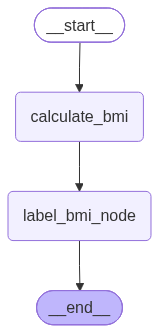

In [23]:
from IPython.display import Image
Image(workflow.get_graph().draw_mermaid_png())